In [99]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

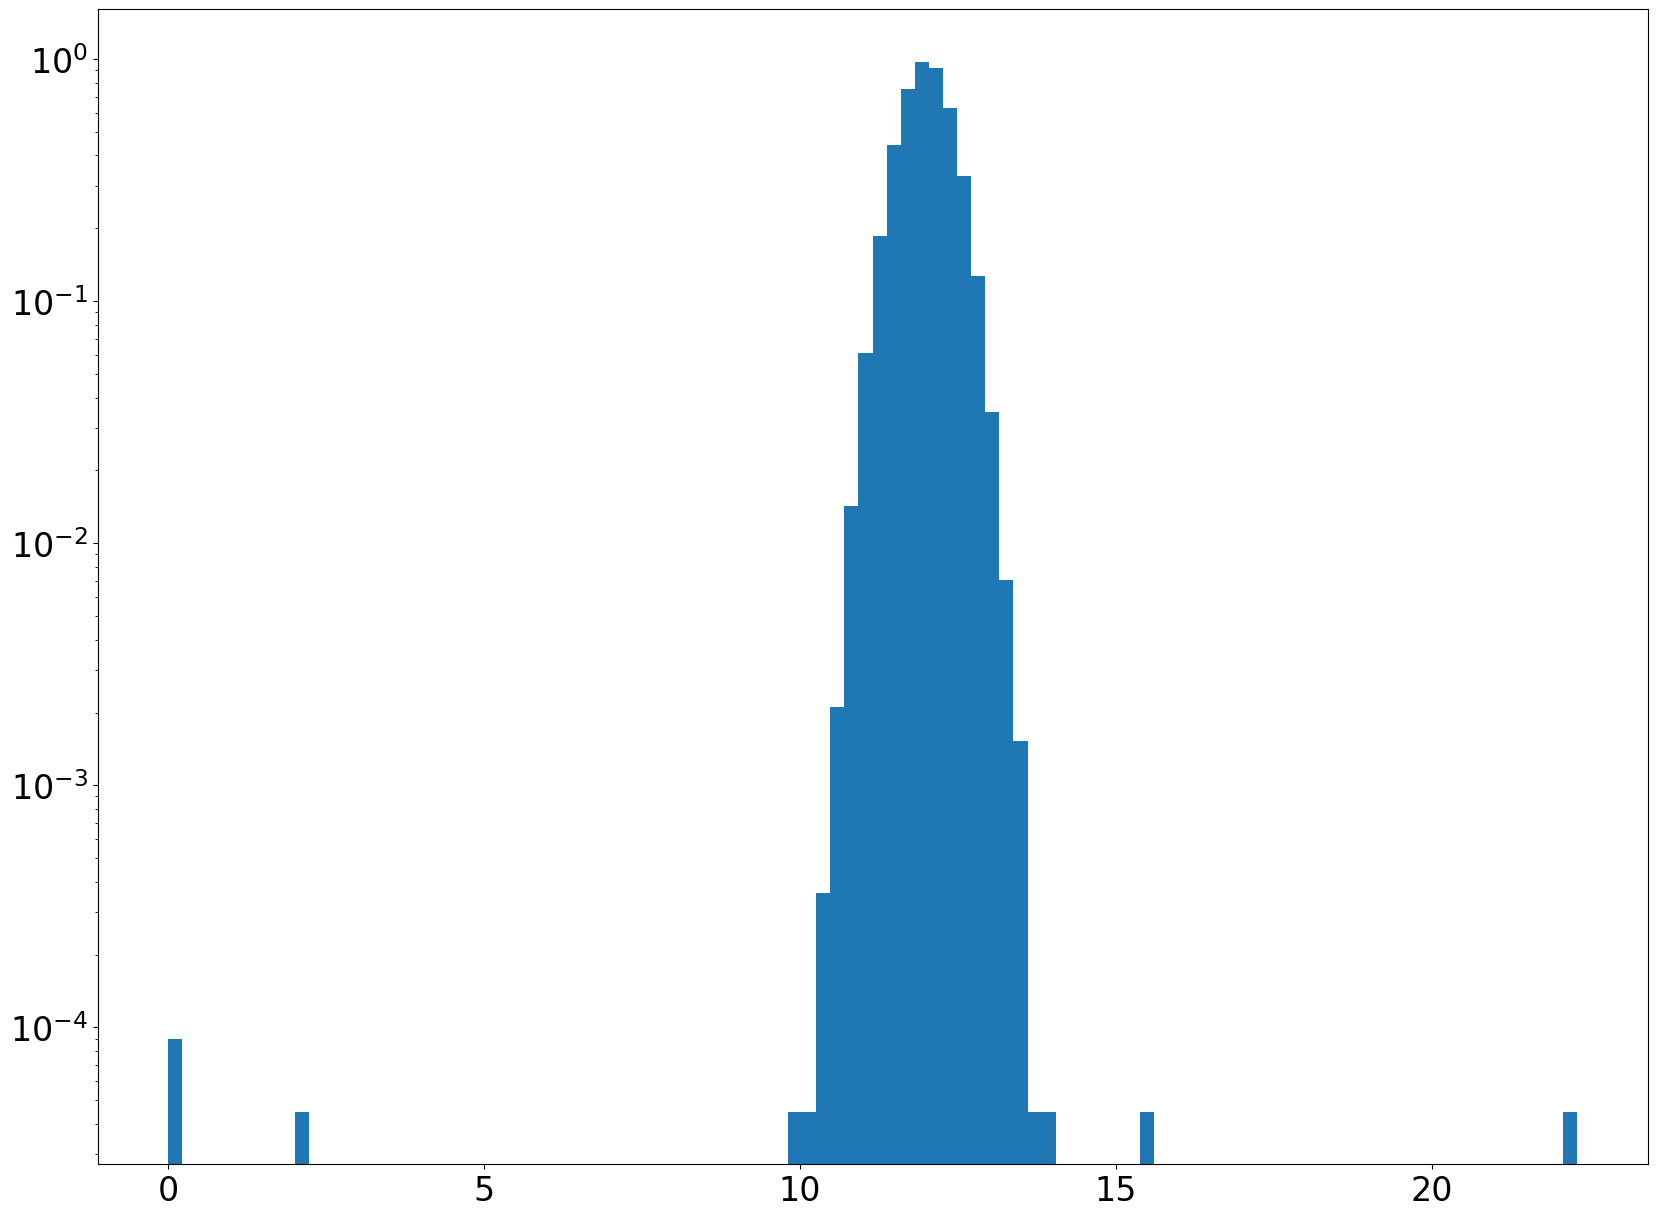

In [100]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

### assuming a temerature reading follows a  normal distribution with an mean 12 K and with a standard deviation of 0.4k, what is the probability the reading is signficant (more than 4 standard deviation from the mean)? I choose this question because knowing the Bad data is not enough. It is critical to know how significant(percentage) the bad data is in the distribution. Also I use this threshold to identify anoualous reading while limiting the rejection of good data.

In [101]:
P = 2 * stats.norm.sf(12+4*0.4, loc = 12, scale = 0.4) 
print(P)

6.334248366623996e-05


Temperature ~ N(12,0.4^2). Rejected a reading if |T-12|>4(0.4) = 1.6k. Therefore, probability of rejecting a good reading is p=P(T<10.4)+P(T>13.6)=2P(Z>(13.6-12)/0.4) = 2P(Z>4) aprromixately equal to 6.334*10^-5

In [102]:
Tbad = P*100000
Tgood = 100000*(1-2 * stats.norm.sf(12+4*0.4, loc = 12, scale = 0.4))
print("Your Test Bad is",round(Tbad))
print("Your Test Good is",round(Tgood))
TrueN = np.array([10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
TrueB= TrueN.size
rejected = np.abs(d-12)>4*0.4 
good_rejected = np.count_nonzero(rejected[:100000])
bad_rejected = np.count_nonzero(rejected[100000:])
print("good data kept:", 100000- good_rejected)
print("good data reject:",good_rejected)
print("bad data kept:", 8 - bad_rejected)
print("bad data rejected:",bad_rejected)

Your Test Bad is 6
Your Test Good is 99994
good data kept: 99994
good data reject: 6
bad data kept: 1
bad data rejected: 7


In [103]:
P = 2 * stats.norm.sf(12+4*0.3, loc = 12, scale = 0.4) 
Tbad = P*100000
Tgood = 100000*(1-2 * stats.norm.sf(12+4*0.3, loc = 12, scale = 0.4))
print("Your Test Bad is",round(Tbad))
print("Your Test Good is",round(Tgood))

Your Test Bad is 270
Your Test Good is 99730


In [104]:
P = 2 * stats.norm.sf(12+4*0.5, loc = 12, scale = 0.4) 
Tbad = P*100000
Tgood = 100000*(1-2 * stats.norm.sf(12+4*0.5, loc = 12, scale = 0.4))
print("Your Test Bad is",Tbad)
print("Your Test Good is",Tgood)

Your Test Bad is 0.05733031437583865
Your Test Good is 99999.94266968562


### b) Because at 3 sigma, approximately 270 good readings are expected to be rejected. At 4 sigma, around 6.33 are expected to be rejected, and 5 sigma threshold,only around 0.057 are expected to be rejected. Therefore, increase the threshold actaully decreases the number of good readings good readings incorrectly discarded. This expectation can be predicted from the guassian tail probability, although the actual count fluctuates. 

### C) yes, some bad readings are accectable. At 4 sig threshold, for example, the injected bad reading 12.7 is kept in this case because it lies only 1.75 sd from 12K. Lowering the threshold leads to rejection of more bad readings, but it also rejects more good readings.Because bad reading overlaps with the good data distribution, temperature alone cannot perfectly exclude them. 

### For a stationary object, the measurement errors in x and y directions are independent Gaussian variables that both have 0 mean and standard deviation 1 arcsecond, what displacement has the same background tail probability as a gaussian 5 sigma event (what displacement has the background that is significant)? 

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_123/2121784878.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
/tmp/ipykernel_123/2121784878.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta$x arcseconds", fontsize = 18)


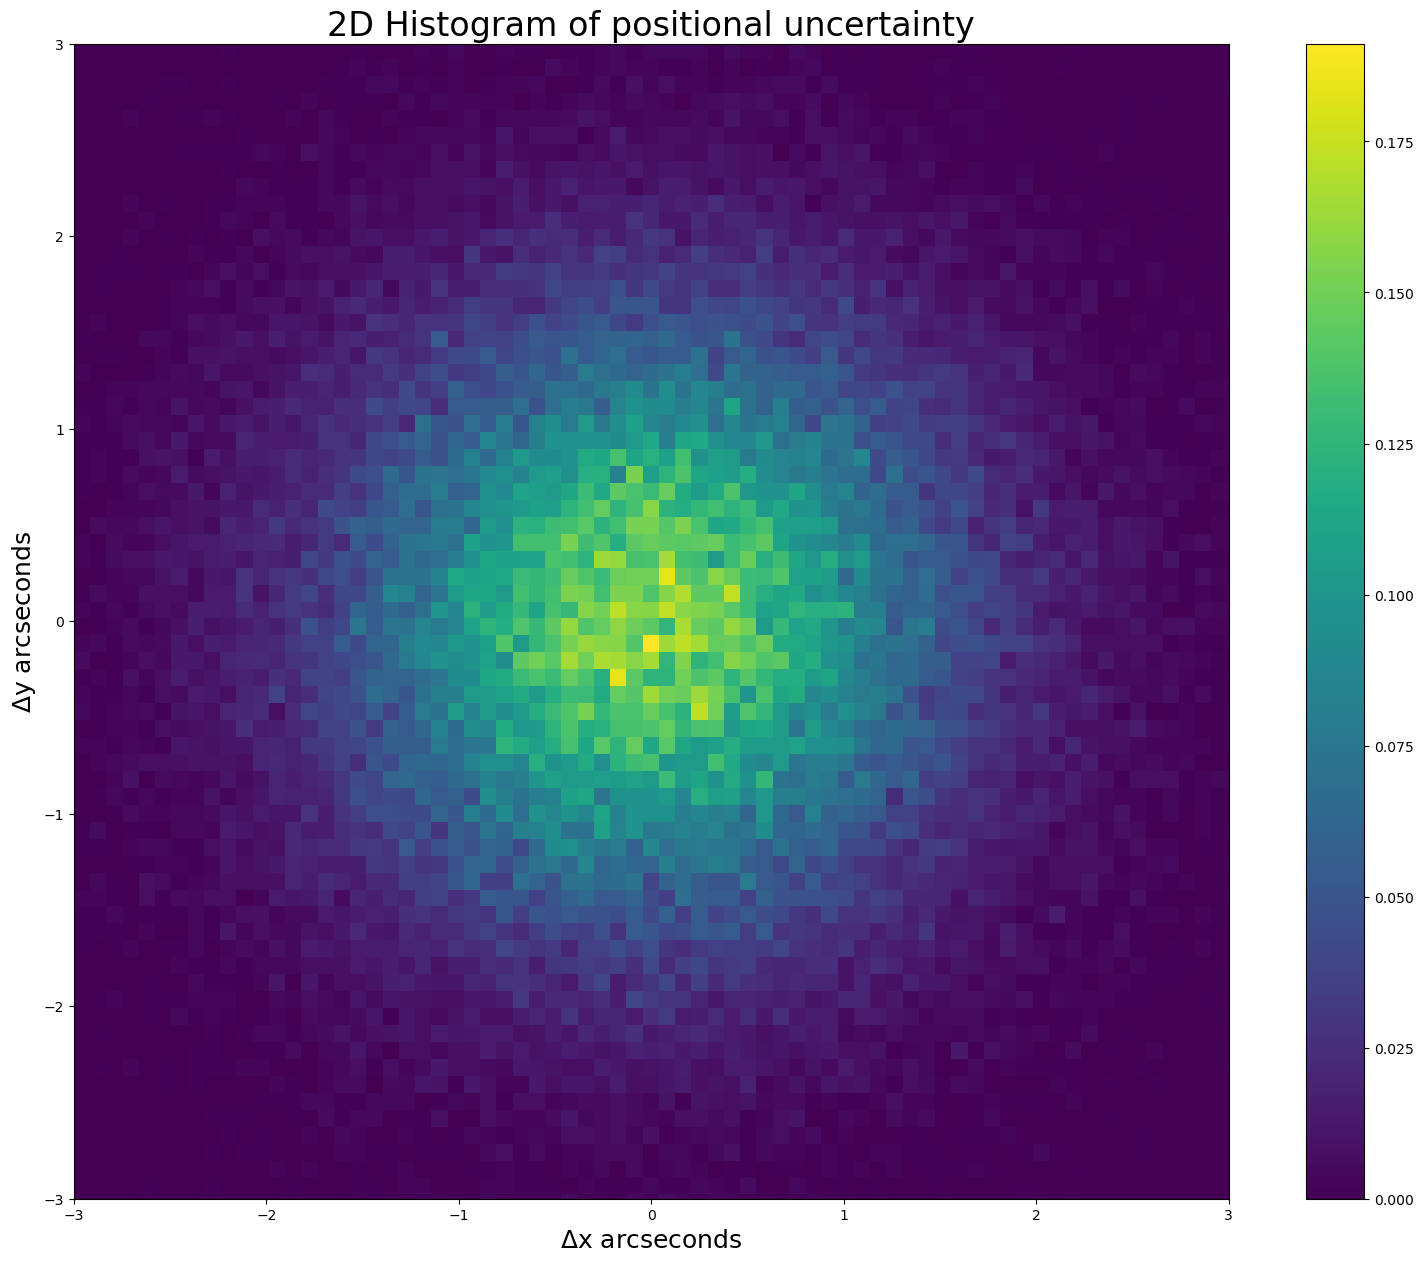

In [105]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

In [106]:
p5 = stats.norm.sf(5) 
r5 = stats.rayleigh.isf(p5,scale=1)
print("5-sigma displacement:", r5, "arcseconds") 

5-sigma displacement: 5.489079776062419 arcseconds


### The distance follows a Rayleigh distribution with scale s = 1 arcsecond: f(r) = (r/s^2)* e^(-r^2/2s^2),r>=0. therfore the tail probability will be P(R>r)= integral from r to infinity f(r)dr = e^(-r^2/2s^2). Next we compute guassian 5 sigma significance, which is: p = P(Z>5) = 2.87*10^-7. then we plug p5 into the tail probability equation to get r and we get r is equal to 5.49 arcsecond. 

### Problem 3

### If there were no moon shadow, we want to know what's the (how significant is the background) probability for observing 6800 cosmics rays in 15 days or fewer cosmic rays when we expected an averge 7200 cosmics rays per 15 days.

In [107]:
P = stats.poisson.cdf(6800,7200)
print(P)

1.0133280183917768e-06


### first of all the average is equal to 1 (count/min)*60(min/hour)*8(hours/day)*15(days)=7200, and since it is discrete, we use a poisson sum. Thus we compute formula P (X <= 6800) = sum from 0 to 6800 (lambda^n times e^- lambda)/ n!, where lambda is 7200, n is the sum index from 0 to 6800. 

In [108]:
Ppossion = stats.poisson.cdf(6800,7200)
sigma = stats.norm.ppf(1- Ppossion,loc=0,scale=1)
print("significance:",sigma)
print("Background probability:",Ppossion)

significance: 4.750747965778662
Background probability: 1.0133280183917768e-06
